# Trade optimisation: a working textbook

Post-trade analysis for a passive-quote, aggressive-hedge spread trade, followed by the simple machine learning
that helps it. Every chapter has the same shape: the question, the definition, the code on data, how to read the
result, the traps, and exercises.

**The data.** Six simulated trading days of one spread trade: passive clips on a slow, large-tick leg (`SPOT`, 2 bps
tick), each fill hedged at once by taking liquidity on a fast leg (`PERP`) that leads it. The tables have the shapes
you build from real data, and the market has effects planted in it, so you can check whether an analysis finds what
is there. Swap in your own exports and the code runs unchanged once the columns match (chapter 1 lists them).

**Conventions used everywhere.**
- `side` is +1 for a buy and -1 for a sell. Every edge, markout and PnL number is signed so that **positive is good for us**.
- Distances are in **ticks of the leg concerned** unless a column says `bps`.
- Times are seconds from the start of each day. Every table has a `day` column, and **ids restart each day**, so a
  join on an id must also join on `day` (chapter 2 shows what happens when it does not).

**How to use it.** Read in order the first time. The exercises at the end of each chapter have no answers here on
purpose: write your prediction, run it, then check. Code you write in the exercises is the part that transfers to
your own data.

## Contents

**Part I. Measuring execution**
1. The tables, and the one join that matters
2. Hedge slippage: where the hedge leg's cost comes from
3. Markouts: definition, horizons, and the hedged version
4. Adverse selection: which fills are toxic, and is toxic bad?
5. Fill probability and queue position
6. Latency: hops, tails, and when it hurts
7. Per-fill attribution: what one hedged fill is worth
8. Statistics hygiene: standard errors that are not lying

**Part II. Simple machine learning for trade optimisation**
9. Framing: prediction, decision, money
10. A fill-probability model
11. A toxicity model, and why the obvious decision loses money
12. Validation: time-blocked splits, overlapping labels, leakage
13. A hedge-cost regression you can explain to a trader

**Checklist and next steps**

In [1]:
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160, "display.max_columns", 30, "display.precision", 3)

DATA = "data"                                  # folder with the six tables (see make_data.py)
TICK = {"SPOT": 0.02, "PERP": 0.01}            # tick size per instrument
QUOTE, HEDGE = "SPOT", "PERP"

# one figure style for the whole notebook: grey = context, blue = the thing being discussed, orange = the contrast
BLUE, ORANGE, GREY, INK2 = "#2a78d6", "#eb6834", "#8f8e88", "#52514e"
plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "axes.axisbelow": True, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.labelsize": 9.5, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 2.0,
})

# Part I. Measuring execution

## 1. The tables, and the one join that matters

**Question.** What do I need in front of me before I can say anything about a fill?

Five tables. These are what you would build from your own exports (exchange or gateway audit for fills and order
events, market data for books and trades, the strategy's log for fair value):

| Table | One row per | Columns used here |
| --- | --- | --- |
| `fills` | our fill | `day, id, order_id, inst, side, price, qty, maker, fee, t, tag, parent` (a hedge fill's `parent` = the quote fill it hedges) |
| `orders` | our order | `day, id, inst, side, price, qty, filled, status, tag, t_submit, t_arrive, t_ack, t_cancel_req, t_cancel_arrive, t_done, mid_decision, mid_arrive, ahead0, cancel_reject, k` |
| `bbo` | change of best bid/ask | `day, inst, t, bid, ask, mid` |
| `trades` | market trade print | `day, inst, t, side` (aggressor), `price, qty` |
| `fair` | strategy log line | `day, t, value` (the strategy's fair value for SPOT) |

Two columns in `fills` (`mid, bid, ask, bid_qty, ask_qty`) are the book just before each fill. Real fill exports
usually do not have them; you attach them yourself with an **as-of join**: for each fill, the last book state at or
before its timestamp. That join, done correctly, is most of post-trade analysis.

In [2]:
fills  = pd.read_csv(f"{DATA}/fills.csv.gz")
orders = pd.read_csv(f"{DATA}/orders.csv.gz")
bbo    = pd.read_csv(f"{DATA}/bbo.csv.gz")
trades = pd.read_csv(f"{DATA}/trades.csv.gz")
fair   = pd.read_csv(f"{DATA}/fair.csv.gz")

for name, df in [("fills", fills), ("orders", orders), ("bbo", bbo), ("trades", trades), ("fair", fair)]:
    print(f"{name:7s} {len(df):>8,} rows   {', '.join(df.columns)}")
print()
print(fills.groupby(["inst", "tag", "maker"]).size().rename("fills"))

fills      4,405 rows   id, order_id, inst, side, price, qty, maker, fee, t, t_local, mid, bid, ask, bid_qty, ask_qty, tag, parent, day
orders    45,130 rows   id, inst, side, price, qty, filled, tif, post_only, status, reason, tag, parent, t_submit, t_arrive, t_ack, t_cancel_req, t_cancel_arrive, t_done, mid_decision, mid_arrive, ahead0, level0, cancel_reject, k, day
bbo       86,071 rows   t, bid, ask, mid, inst, day
trades   121,370 rows   t, side, price, qty, inst, day
fair     212,404 rows   t, value, day

inst  tag    maker
PERP  hedge  False    2350
SPOT  quote  True     2055
Name: fills, dtype: int64


### The as-of join, two ways

`pd.merge_asof` is the readable version. It needs both sides sorted by time and a `by=` key so that day 3's fills
are never matched to day 2's book. For repeated lookups ("the mid 5 seconds after every fill") a sorted array and
`np.searchsorted` does the same thing faster; `mid_at` below is that, and the rest of the notebook uses it.

Here the fills table already records the book just before each fill, so the join can be checked against it. That
check is a habit worth keeping: whenever you can, test a join against a value you already know.

In [3]:
q = fills[fills.tag == "quote"].sort_values("t", kind="stable")
book = bbo[bbo.inst == QUOTE].sort_values("t", kind="stable")[["day", "t", "bid", "ask", "mid"]]

check = {}
for exact in (False, True):
    j = pd.merge_asof(q, book.rename(columns={"bid": "bid_j", "ask": "ask_j", "mid": "mid_j"}),
                      on="t", by="day", direction="backward", allow_exact_matches=exact)
    diff = (j.mid_j - j.mid) / TICK[QUOTE]
    check["at or before the fill" if exact else "strictly before the fill"] = {
        "same mid as recorded": np.isclose(diff, 0).mean(), "within half a tick": (diff.abs() <= 0.5 + 1e-9).mean(),
        "average error in our favour, ticks": (diff * j.side).mean()}
    if not exact:
        joined = j
same_ts = pd.Series(list(zip(q.day, q.t))).isin(set(zip(book.day, book.t))).mean()
print(f"{same_ts:.0%} of quote fills share their exact timestamp with a book update")
display(pd.DataFrame(check).T.round(3))

# the fast version: one sorted array per (instrument, day). kind="stable" keeps same-timestamp rows in arrival order.
_BOOKS = {k: (g.t.values, g.bid.values, g.ask.values, g.mid.values) for k, g in bbo.sort_values("t", kind="stable").groupby(["inst", "day"])}


def _idx(inst, day, t, strict=False):
    tt = _BOOKS[(inst, day)][0]
    k = np.searchsorted(tt, np.asarray(t, dtype=float), side="left" if strict else "right") - 1
    return np.clip(k, 0, len(tt) - 1)


def mid_at(inst, day, t, strict=False):
    # Mid of `inst` on `day` at times t: the last update at or before t (strictly before if strict=True).
    return _BOOKS[(inst, day)][3][_idx(inst, day, t, strict)]


def bbo_at(inst, day, t, strict=False):
    k = _idx(inst, day, t, strict)
    b = _BOOKS[(inst, day)]
    return b[1][k], b[2][k]


fast = np.concatenate([mid_at(QUOTE, d, g.t.values, strict=True) for d, g in joined.groupby("day", sort=True)])
slow = np.concatenate([g.mid_j.values for _, g in joined.groupby("day", sort=True)])
print("searchsorted version matches merge_asof:", np.allclose(fast, slow))

62% of quote fills share their exact timestamp with a book update


,same mid as recorded,within half a tick,"average error in our favour, ticks"
strictly before the fill,0.568,0.892,0.317
at or before the fill,0.756,0.950,-0.154


searchsorted version matches merge_asof: True


**Reading it.** The join gets the recorded book exactly right for only about half to three quarters of fills, and
not because the code is wrong. Most fills share their timestamp with book updates: a sweep that fills us also prints
several level changes in the same instant. "Strictly before" misses the updates earlier in that instant; "at or
before" includes the ones after the fill. With timestamps alone the book just before the fill cannot be recovered.
Real feeds carry a sequence number per message for exactly this; join on (timestamp, sequence). This notebook uses
the recorded book columns where it needs the book at the fill, and strictly-before lookups elsewhere.

**Traps.**
- **Equal timestamps.** As above. Decide which side of a tie you want, say so (`allow_exact_matches`, `strict=`),
  and use sequence numbers when the data has them.
- **Unstable sorts.** `sort_values("t")` may reorder rows that share a timestamp, which scrambles the order of a sweep
  and gives the wrong "last" state. Use `kind="stable"`, or sort on (timestamp, sequence).
- **Clock sources.** Exchange time, gateway time and your own receive time are different clocks. Join exchange-stamped
  fills to exchange-stamped book data. Your own receive time is later by the feed latency, and joining on it quietly
  uses the future (chapter 12 shows the damage).
- **Ids restart.** Order and fill ids repeat across days, sessions or gateway restarts. Join on `(day, id)`.

**Exercises.**
1. Take one fill where the two settings disagree and print every `bbo` and `trades` row at its timestamp. Reconstruct
   what happened in that instant, in order. What extra column would have let the join get it right?
2. Write `depth_at(inst, day, t, side, n)` returning total size within n ticks of the touch. What would you need that
   the `bbo` table does not have?

## 2. Hedge slippage: where the hedge leg's cost comes from

**Question.** When a quote fills and we hedge by crossing on the other leg, what does that cost, and why?

For an aggressive order, three prices matter: the mid when we **decided** (`mid_decision`), the mid when the order
**arrived** at the exchange (`mid_arrive`), and the price we **paid** (volume-weighted over its fills).

$$\text{total} = \underbrace{\text{side}\cdot(\text{mid}_\text{arrive} - \text{mid}_\text{decision})}_{\text{delay cost}} + \underbrace{\text{side}\cdot(\text{vwap} - \text{mid}_\text{arrive})}_{\text{crossing cost}}$$

Both are costs here (positive = bad), quoted in bps of the decision mid. Delay cost is what latency costs you;
crossing cost is half the spread plus whatever you walk through the book.

For a spread trade there is a third benchmark that matters more: the hedge leg's mid **at the moment the quote
filled**. That is the price at which the spread was actually locked. Everything that happens between the quote fill
and the hedge fill (feed delay, our reaction, order entry) shows up against it.

In [4]:
h_orders = orders[orders.tag == "hedge"].copy()
h_fills = fills[fills.tag == "hedge"].assign(notional=lambda x: x.price * x.qty)

# --- the wrong join first: ids restart every day
wrong = h_fills.groupby("order_id").agg(notional=("notional", "sum"), filled_qty=("qty", "sum"))
w = h_orders.join(wrong, on="id")
w_cost = w.side * (w.notional / w.filled_qty - w.mid_arrive) / w.mid_decision * 1e4
print(f"joined on order id only:  crossing cost ranges {w_cost.min():.1f} to {w_cost.max():.1f} bps  <- impossible for a 1 bp half-spread")

# --- the right join: (day, order id)
agg = h_fills.groupby(["day", "order_id"]).agg(notional=("notional", "sum"), filled_qty=("qty", "sum"))
hdg = h_orders.join(agg, on=["day", "id"])
hdg["vwap"] = hdg.notional / hdg.filled_qty
hdg["delay_ms"] = (hdg.t_arrive - hdg.t_submit) * 1e3
hdg["delay_cost"] = hdg.side * (hdg.mid_arrive - hdg.mid_decision) / hdg.mid_decision * 1e4
hdg["cross_cost"] = hdg.side * (hdg.vwap - hdg.mid_arrive) / hdg.mid_decision * 1e4
hdg["total_cost"] = hdg.delay_cost + hdg.cross_cost
print(f"joined on (day, order id): crossing cost ranges {hdg.cross_cost.min():.1f} to {hdg.cross_cost.max():.1f} bps\n")
print(hdg[["delay_ms", "delay_cost", "cross_cost", "total_cost"]].describe(percentiles=[0.1, 0.5, 0.9]).round(2))

joined on order id only:  crossing cost ranges -83.3 to 95.6 bps  <- impossible for a 1 bp half-spread
joined on (day, order id): crossing cost ranges 0.5 to 4.0 bps

       delay_ms  delay_cost  cross_cost  total_cost
count   2058.00     2058.00     2058.00     2058.00
mean      12.51        0.01        1.18        1.18
std        9.95        0.15        0.40        0.41
min        7.32       -2.00        0.50        0.00
10%        9.47        0.00        0.99        0.99
50%       11.14        0.00        1.00        1.00
90%       13.63        0.00        1.59        1.68
max      123.48        1.00        4.00        4.00


Now the spread view: pair every quote fill with its hedge fills (`parent`) and measure the hedge against the hedge
leg's mid at the quote fill's time.

In [5]:
qf = fills[fills.tag == "quote"].copy()
pair = h_fills.groupby(["day", "parent"]).agg(h_notional=("notional", "sum"), h_qty=("qty", "sum"),
                                              h_side=("side", "first"), h_t=("t", "max"), h_fee=("fee", "sum"))
qf = qf.join(pair, on=["day", "id"])
qf = qf.sort_values(["day", "t"]).reset_index(drop=True)           # sorted by day then time, so per-day arrays line up
qf["hedge_mid_at_fill"] = np.concatenate([mid_at(HEDGE, d, g.t.values, strict=True) for d, g in qf.groupby("day")])
qf["h_vwap"] = qf.h_notional / qf.h_qty
qf["hedge_delay_ms"] = (qf.h_t - qf.t) * 1e3
qf["hedge_cost_bps"] = qf.h_side * (qf.h_vwap - qf.hedge_mid_at_fill) / qf.hedge_mid_at_fill * 1e4
print("quote fills without a hedge:", qf.h_qty.isna().sum())
print(qf[["hedge_delay_ms", "hedge_cost_bps"]].describe(percentiles=[0.1, 0.5, 0.9]).round(2))

qf["delay_bucket"] = pd.qcut(qf.hedge_delay_ms, 5)
tab = qf.groupby("delay_bucket", observed=True).hedge_cost_bps.agg(["mean", "median", "count"])
tab["se"] = qf.groupby("delay_bucket", observed=True).hedge_cost_bps.std() / np.sqrt(tab["count"])
tab

quote fills without a hedge: 0
       hedge_delay_ms  hedge_cost_bps
count         2055.00         2055.00
mean            18.52            1.18
std             12.04            0.41
min             11.22           -0.00
10%             14.31            0.99
50%             16.64            1.00
90%             19.89            1.66
max            202.81            3.99


,mean,median,count,se
delay_bucket,,,,
"(11.223, 15.05]",1.147,1.002,411,0.018
"(15.05, 16.18]",1.144,1.002,411,0.020
"(16.18, 17.137]",1.188,1.003,411,0.020
"(17.137, 18.507]",1.206,1.002,411,0.020
"(18.507, 202.807]",1.224,1.003,411,0.022


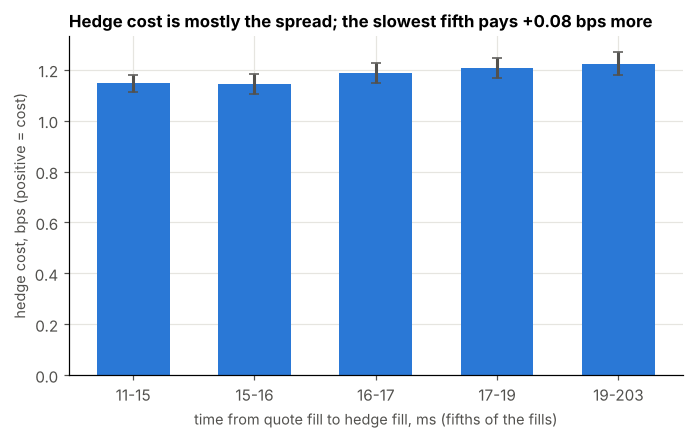

In [6]:
fig, ax = plt.subplots()
x = np.arange(len(tab))
ax.bar(x, tab["mean"], yerr=1.96 * tab["se"], color=BLUE, width=0.6, error_kw={"ecolor": INK2, "capsize": 3})
ax.set_xticks(x, [f"{iv.left:.0f}-{iv.right:.0f}" for iv in tab.index])
ax.set_xlabel("time from quote fill to hedge fill, ms (fifths of the fills)")
ax.set_ylabel("hedge cost, bps (positive = cost)")
ax.set_title(f"Hedge cost is mostly the spread; the slowest fifth pays {tab['mean'].iloc[-1] - tab['mean'].iloc[0]:+.2f} bps more")
plt.show()

**Reading it.** Most of the hedge cost is crossing the spread, which no amount of speed removes. Delay adds a little,
concentrated in the slow tail. In your own data, check which of the two dominates before deciding whether latency
work or hedge-order design is the better use of time.

**Traps.**
- A hedge that walks the book has a vwap but also several fill times; use the last for delay.
- Partial hedges and unhedged remainders must be counted, not dropped, or the cost looks better than it is.
- The hedge leg moving between your quote fill and your hedge is not "bad luck" if the hedge leg leads: it is
  information you are paying for. Chapter 4 measures it.

**Exercises.**
1. Split `cross_cost` by the hedge size relative to the size at the touch (`fills` has `bid_qty`, `ask_qty` for hedge
   fills). At what ratio does walking the book start to matter?
2. Would resting the hedge passively for 50 ms first, then crossing, have been cheaper? Sketch how you would estimate
   it from these tables, and what you cannot know from them.

## 3. Markouts: definition, horizons, and the hedged version

**Question.** After a fill, did the market move for us or against us, and over what time?

The markout of a fill at horizon $h$, in ticks:

$$m(h) = \text{side}\cdot\frac{\text{mid}(t+h) - \text{price}}{\text{tick}}$$

At $h = 0$ it is the edge at the fill (how far inside the mid we traded). As $h$ grows it adds the move that followed.
Averaged over many fills and plotted against $h$, it is the **markout curve**.

For a hedged trade, the quoted leg's own markout also contains the market move that the hedge cancels. The **spread
markout** removes it:

$$s(h) = m(h) - \text{side}\cdot\frac{\text{price}}{\text{tick}}\cdot\left(\frac{\text{hedge mid}(t+h)}{\text{hedge mid}(t)} - 1\right)$$

It is what the hedged position made over $h$, before hedging costs.

In [7]:
HORIZONS = [0, 0.1, 0.5, 1, 2, 5, 15, 30, 60, 120, 300]


def add_markouts(df, horizons=HORIZONS):
    # Adds m<h> (own-leg) and s<h> (spread) markouts in ticks of the quoted leg, for quote fills in df.
    df = df.sort_values(["day", "t"]).reset_index(drop=True)
    out = {f"{p}{h:g}": np.empty(len(df)) for h in horizons for p in "ms"}
    pos = 0
    for d, g in df.groupby("day", sort=True):
        t, s, p = g.t.values, g.side.values, g.price.values
        h0 = mid_at(HEDGE, d, t, strict=True)
        for h in horizons:
            m = s * (mid_at(QUOTE, d, t + h) - p) / TICK[QUOTE] if h > 0 else s * (g.mid.values - p) / TICK[QUOTE]
            hr = mid_at(HEDGE, d, t + h) / h0 - 1 if h > 0 else 0.0
            out[f"m{h:g}"][pos:pos + len(g)] = m
            out[f"s{h:g}"][pos:pos + len(g)] = m - s * p * hr / TICK[QUOTE]
        pos += len(g)
    end = df.groupby("day").t.transform("max")         # drop horizons that run past the end of the day
    for h in horizons:
        for p in "ms":
            out[f"{p}{h:g}"][(df.t + h > end).values] = np.nan
    return pd.concat([df, pd.DataFrame(out)], axis=1)


qf = add_markouts(qf)


def curve(df, prefix, horizons=HORIZONS):
    rows = []
    for h in horizons:
        v = df[f"{prefix}{h:g}"].dropna()
        rows.append({"h": h, "mean": v.mean(), "se": v.std() / np.sqrt(len(v)), "median": v.median(),
                     "p10": v.quantile(0.1), "p90": v.quantile(0.9), "n": len(v)})
    return pd.DataFrame(rows).set_index("h")


own, spr = curve(qf, "m"), curve(qf, "s")
pd.concat({"own-leg markout": own[["mean", "median", "p10", "p90"]], "spread markout": spr[["mean", "median", "p10", "p90"]]}, axis=1).round(2)

own-leg markout                    spread markout                   
                 mean median   p10   p90           mean median   p10   p90
h                                                                         
0.0              0.08   0.00  -1.0   1.0           0.08   0.00 -1.00  1.00
0.1             -0.28   0.00  -1.0   0.5          -0.26   0.00 -1.25  0.75
0.5             -0.65  -0.50  -2.0   0.5          -0.63  -0.50 -2.00  0.75
1.0             -0.70  -0.50  -2.5   1.0          -0.67  -0.50 -2.50  1.00
2.0             -0.65  -0.50  -3.0   1.0          -0.64  -0.50 -3.00  1.25
5.0             -0.41   0.00  -3.5   2.5          -0.35  -0.25 -3.25  2.50
15.0             0.38   0.00  -4.0   5.0           0.53   0.25 -3.50  5.00
30.0             1.05   1.00  -5.0   7.5           1.09   1.00 -4.00  6.49
60.0             2.18   2.00  -5.0   9.0           2.30   2.25 -3.50  8.00
120.0            2.04   1.75  -7.0  11.0           2.10   2.50 -4.74  8.49
300.0            1.95   1.50 -11.0  15.5           2.38   2.25 -4.00  9.00

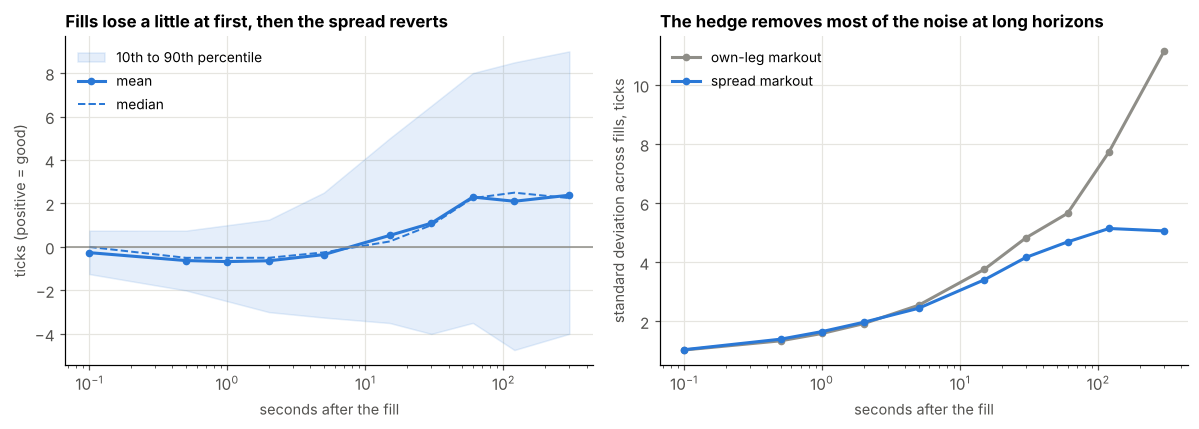

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
hs = [h for h in HORIZONS if h > 0]
ax[0].fill_between(hs, spr.loc[hs, "p10"], spr.loc[hs, "p90"], color=BLUE, alpha=0.12, label="10th to 90th percentile")
ax[0].plot(hs, spr.loc[hs, "mean"], "-o", color=BLUE, ms=4, label="mean")
ax[0].plot(hs, spr.loc[hs, "median"], "--", color=BLUE, lw=1.3, label="median")
ax[0].axhline(0, color=GREY, lw=1)
ax[0].set_xscale("log"); ax[0].set_xlabel("seconds after the fill"); ax[0].set_ylabel("ticks (positive = good)")
ax[0].set_title("Fills lose a little at first, then the spread reverts")
ax[0].legend(loc="upper left")
sd = pd.DataFrame({"own leg": [qf[f"m{h:g}"].std() for h in hs], "spread": [qf[f"s{h:g}"].std() for h in hs]}, index=hs)
ax[1].plot(hs, sd["own leg"], "-o", color=GREY, ms=4, label="own-leg markout")
ax[1].plot(hs, sd["spread"], "-o", color=BLUE, ms=4, label="spread markout")
ax[1].set_xscale("log"); ax[1].set_xlabel("seconds after the fill"); ax[1].set_ylabel("standard deviation across fills, ticks")
ax[1].set_title("The hedge removes most of the noise at long horizons")
ax[1].legend()
plt.tight_layout(); plt.show()

**Reading it.** This trade's fills mark out slightly negative over the first few seconds and positive after about
15 seconds, as the spread reverts. The sign of "the markout" therefore depends entirely on the horizon you pick. For a
trade that holds for minutes, a short-horizon markout measures *when* you got filled within a move, not whether the
trade was good.

Pick horizons from the trade, not by habit: one just after your reaction time, one around the hedge leg's lead, one
around the spread's half-life, one near your typical holding time.

**Traps.**
- **Mean versus median.** A few large moves dominate the mean. Report both, and the 10th percentile, which is what a
  bad day looks like.
- **Mid versus fair value.** Against the mid, a large-tick leg's markout jumps in half-ticks as the book flickers.
  Against a microprice or your own fair value it is smoother, but then it partly measures your model.
- **End of data.** Fills less than $h$ seconds before the end have no $h$-second markout. Drop them, as here, rather
  than marking them to the last price.

**Exercises.**
1. Plot the curve separately for buys and sells. If they differ a lot, what does that suggest about the fair value?
2. Compute the markout against the strategy's logged fair value (`fair` table) instead of the mid. Which horizons change?
3. Over what horizon does the average spread markout cross zero? Before computing it, write down your guess from the
   chart, and what in the market sets that horizon.

## 4. Adverse selection: which fills are toxic, and is toxic bad?

**Question.** Are some fills systematically worse than others, and can we see it coming?

Adverse selection is the tendency to be filled exactly when the price is about to move against you: whoever trades
with your resting order often knows something. The tool is a **conditional markout table**: bucket fills by something
known *at the fill time*, and compare markouts across buckets.

Features known at the moment of the fill, all signed so that positive means "in our favour":
- `quote_ret_2s`: the quoted leg's move over the previous 2 seconds. Negative = it was already moving against us (momentum into the fill).
- `hedge_ret_2s`: the same for the hedge leg, which leads. Negative = the leading leg had already moved against us.
- `flow_5s`: signed traded volume on the quoted leg over the previous 5 seconds, in our direction.
- `lean`: book imbalance at the touch, signed toward our side.

In [9]:
_TAPE = {k: (g.t.values, np.r_[0.0, np.cumsum(g.side.values * g.qty.values)]) for k, g in trades.sort_values("t", kind="stable").groupby(["inst", "day"])}


def signed_flow(inst, day, t, window):
    # Buy volume minus sell volume printed on `inst` in (t - window, t].
    tt, cs = _TAPE[(inst, day)]
    return cs[np.searchsorted(tt, t, side="right")] - cs[np.searchsorted(tt, t - window, side="right")]


feat = []
for d, g in qf.groupby("day", sort=True):
    t, s = g.t.values, g.side.values
    feat.append(pd.DataFrame({
        "quote_ret_2s": s * (mid_at(QUOTE, d, t, strict=True) / mid_at(QUOTE, d, t - 2) - 1) * 1e4,
        "hedge_ret_2s": s * (mid_at(HEDGE, d, t, strict=True) / mid_at(HEDGE, d, t - 2) - 1) * 1e4,
        "flow_5s": s * signed_flow(QUOTE, d, t - 1e-9, 5.0),
        "lean": s * (g.bid_qty.values - g.ask_qty.values) / (g.bid_qty.values + g.ask_qty.values),
    }, index=g.index))
qf = qf.join(pd.concat(feat))


def conditional(df, by, cols, q=5):
    g = df.groupby(pd.qcut(df[by], q, duplicates="drop"), observed=True)
    out = g[cols].mean().add_suffix("_mean")
    for c in cols:
        out[c + "_se"] = g[c].std() / np.sqrt(g[c].count())
    out["n"] = g.size()
    return out


cols = ["s1", "s5", "s30", "s120"]
tables = {f: conditional(qf, f, cols) for f in ["quote_ret_2s", "hedge_ret_2s", "flow_5s", "lean"]}
tables["quote_ret_2s"].round(2)

,s1_mean,s5_mean,s30_mean,s120_mean,s1_se,s5_se,s30_se,s120_se,n
quote_ret_2s,,,,,,,,,
"(-26.053, -4.011]",-1.20,-0.71,1.12,2.62,0.10,0.13,0.22,0.24,411
"(-4.011, -1.995]",-0.90,-0.76,0.75,2.07,0.08,0.12,0.20,0.28,411
"(-1.995, 0.0]",-0.58,-0.19,1.12,2.03,0.05,0.08,0.15,0.19,741
"(0.0, 1.0]",-0.48,-0.39,0.93,1.12,0.21,0.28,0.50,0.58,83
"(1.0, 9.997]",-0.12,0.14,1.40,1.93,0.07,0.13,0.22,0.28,409


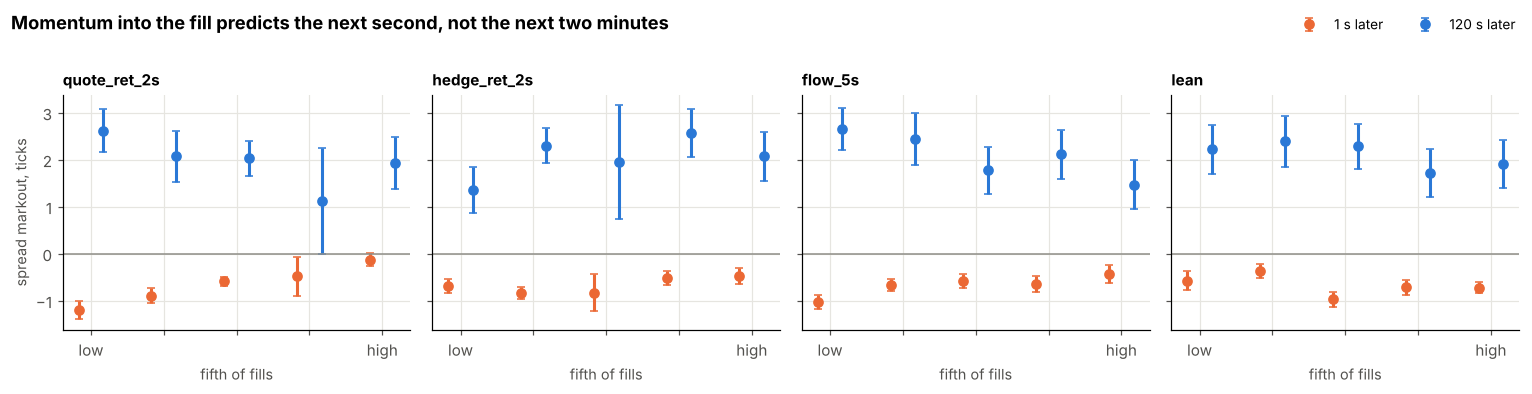

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), sharey=True)
for ax, (f, tb) in zip(axes, tables.items()):
    x = np.arange(len(tb))
    for c, col, off in (("s1", ORANGE, -0.17), ("s120", BLUE, 0.17)):
        ax.errorbar(x + off, tb[f"{c}_mean"], yerr=1.96 * tb[f"{c}_se"], fmt="o", color=col, capsize=2.5, label=f"{c[1:]} s later")
    ax.axhline(0, color=GREY, lw=1)
    ax.set_xticks(x, ["low", "", "", "", "high"][:len(tb)])
    ax.set_title(f, fontsize=10)
    ax.set_xlabel("fifth of fills")
axes[0].set_ylabel("spread markout, ticks")
hnd, lab = axes[0].get_legend_handles_labels()
fig.legend(hnd, lab, loc="upper right", ncol=2, bbox_to_anchor=(0.995, 1.0))
fig.suptitle("Momentum into the fill predicts the next second, not the next two minutes", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.97)); plt.show()

**Reading it.** Fills that arrive while the quoted leg is already moving against us (`quote_ret_2s` low) and while
flow is running against us (`flow_5s` low) are the most toxic over the next second. That is adverse selection, and
it is visible before the fill. But the same fills are *not* worse two minutes later: the move that filled them is the
dislocation the trade exists to capture, and it reverts.

So "toxic" needs a horizon too. For a market maker who flattens in seconds, those fills are bad. For a spread trade
that holds until the spread reverts, they can be fine or even the best fills. Chapter 11 shows what happens when a
model is trained to avoid them.

### Are our fills worse than everyone else's?

Every market trade has a passive side. The average markout of the market's passive side is a benchmark: if our fills
are much worse at short horizons, we are being selected against more than the average resting order.

In [11]:
rows = []
for d in sorted(trades.day.unique()):
    tr = trades[(trades.inst == QUOTE) & (trades.day == d)]
    ours = qf[qf.day == d]
    for h in [0.5, 1, 5, 30, 120]:
        mk = -tr.side.values * (mid_at(QUOTE, d, tr.t.values + h) - tr.price.values) / TICK[QUOTE]
        mo = ours.side.values * (mid_at(QUOTE, d, ours.t.values + h) - ours.price.values) / TICK[QUOTE]
        rows += [{"who": "market's passive side", "day": d, "h": h, "m": np.average(mk, weights=tr.qty.values)},
                 {"who": "our quote fills", "day": d, "h": h, "m": np.average(mo, weights=ours.qty.values)}]
bench = pd.DataFrame(rows).groupby(["who", "h"]).m.agg(["mean", "std"]).unstack(0)
bench.round(2)

mean                                   std                
who   market's passive side our quote fills market's passive side our quote fills
h                                                                                
0.5                   -0.25           -0.69                  0.04            0.16
1.0                   -0.39           -0.75                  0.06            0.16
5.0                   -0.30           -0.49                  0.09            0.21
30.0                   0.10            1.01                  0.17            0.45
120.0                  0.54            2.12                  0.25            0.57

Our fills are worse than the average passive trade over the first seconds and much better two minutes out. That is
the signature of quoting off another leg's fair value: we are filled when the quoted leg dislocates from the hedge
leg, which is both when the immediate move is against us and when the reversion is largest.

**Traps.**
- **Features must be known at the fill.** Use the book *before* the fill and trades strictly before it. A feature
  that peeks even 1 ms past the fill will look predictive.
- **Bucket on rank, not value.** Quantile buckets keep the counts equal so the error bars are comparable.
- **Many buckets, many chances.** Four features x five buckets x four horizons is 80 numbers; some will look
  significant by chance. Chapter 8 covers this.

**Exercises.**
1. Build the same table with `hedge_ret_0.5s` (half a second). The hedge leg leads the quoted leg here by a fraction
   of a second; what should that do to the short-horizon markouts, and do you see it?
2. Bucket by ladder level `k` (join it from `orders`). Are the outer clips' fills more or less toxic? Why might that be?
3. Pick the most toxic fifth by `quote_ret_2s`. What would it have taken to not be filled there: a faster cancel,
   a wider quote, or a rule? What can these tables tell you about each?

## 5. Fill probability and queue position

**Question.** For an order placed at a given distance from the touch and behind a given queue, how likely is it to
fill?

Every passive order is a bet on two things: being filled, and the fill being good. Chapter 4 was the second. This is
the first, measured on all our orders, filled or not. The distance from the touch is measured at the moment the order
arrives at the exchange, from the book at that time.

In [12]:
qo = orders[(orders.tag == "quote") & orders.status.isin(["filled", "cancelled"])].copy()
qo = qo.sort_values(["day", "t_arrive"]).reset_index(drop=True)
bid = np.empty(len(qo)); ask = np.empty(len(qo)); pos = 0
for d, g in qo.groupby("day", sort=True):
    b, a = bbo_at(QUOTE, d, g.t_arrive.values)
    bid[pos:pos + len(g)], ask[pos:pos + len(g)] = b, a
    pos += len(g)
qo["dist"] = np.round(np.where(qo.side > 0, bid - qo.price, qo.price - ask) / TICK[QUOTE])   # ticks behind the touch; 0 = joining it
qo["spread_ticks"] = np.round((ask - bid) / TICK[QUOTE])
qo["got_fill"] = (qo.filled > 0).astype(int)
qo["life_s"] = qo.t_done - qo.t_arrive
print(f"{len(qo):,} quote orders; {qo.got_fill.mean():.1%} received a fill; median life {qo.life_s.median():.2f} s")

by_dist = qo[qo.dist.between(-1, 6)].groupby("dist").got_fill.agg(["mean", "count"])
at_touch = qo[qo.dist == 0]
by_queue = at_touch.groupby(pd.qcut(at_touch.ahead0, 5, duplicates="drop"), observed=True).got_fill.agg(["mean", "count"])
display(by_dist.round(3)); display(by_queue.round(3))

43,031 quote orders; 4.0% received a fill; median life 0.91 s


,mean,count
dist,,
-1.0,0.573,1324
0.0,0.231,1627
1.0,0.069,2086
2.0,0.024,2913
3.0,0.014,3717
4.0,0.005,4379
5.0,0.003,4623
6.0,0.001,4634


,mean,count
ahead0,,
"(0.999, 31.0]",0.284,331
"(31.0, 74.0]",0.264,322
"(74.0, 136.0]",0.227,326
"(136.0, 229.8]",0.193,322
"(229.8, 614.0]",0.187,326


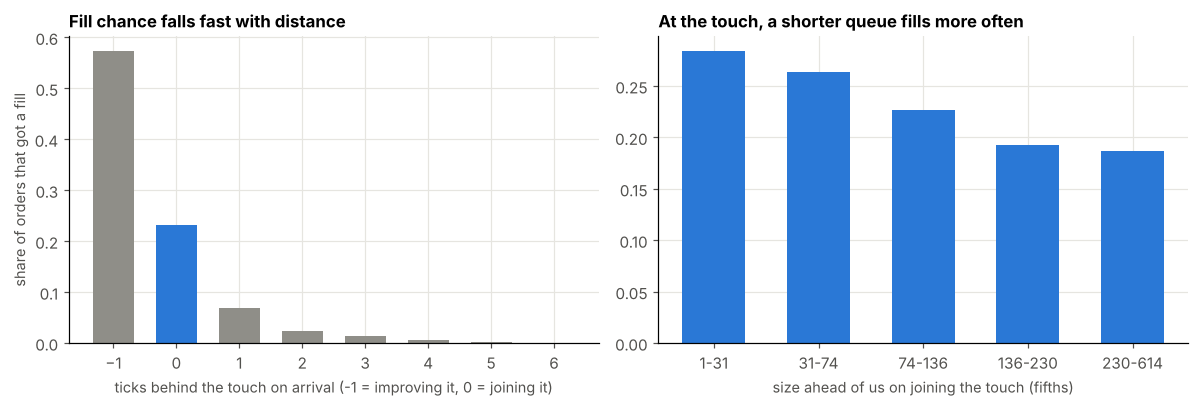

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].bar(by_dist.index, by_dist["mean"], color=[BLUE if d == 0 else GREY for d in by_dist.index], width=0.65)
ax[0].set_xlabel("ticks behind the touch on arrival (-1 = improving it, 0 = joining it)")
ax[0].set_ylabel("share of orders that got a fill")
ax[0].set_title("Fill chance falls fast with distance")
x = np.arange(len(by_queue))
ax[1].bar(x, by_queue["mean"], color=BLUE, width=0.6)
ax[1].set_xticks(x, [f"{iv.left:.0f}-{iv.right:.0f}" for iv in by_queue.index])
ax[1].set_xlabel("size ahead of us on joining the touch (fifths)")
ax[1].set_title("At the touch, a shorter queue fills more often")
plt.tight_layout(); plt.show()

**Reading it.** Distance from the touch dominates; queue position matters at the touch. These two curves are what
turn "move the clip a tick" into an expected change in fills, and together with chapter 4's markouts they price the
move: fewer fills, each one further from fair value, with a different mix of toxic and benign fills.

**Traps.**
- **Order life is a choice, not a feature.** Our orders are cancelled and requoted constantly (a median life under a
  second), so "probability of a fill" means "within the order's life". An order that lives longer fills more for
  that reason alone. Compare like with like, or model fill probability per second of life.
- **`ahead0` comes from a model.** In real data the queue ahead is estimated from level-2 data with an assumption
  about where cancels come from. In this dataset it is the simulator's estimate. Treat queue effects as approximate.
- **You only see the orders you sent.** Distances you never quote have no data. Fill probability there is an
  extrapolation.

**Exercises.**
1. Model fill probability per second of life: bucket orders by `life_s` as well as `dist`. Does the queue effect survive?
2. Do the orders that improve the touch (`dist = -1`) mark out worse once filled? Join their fills to chapter 3's markouts.
3. Estimate, from these two tables alone, how many fills a day you would lose by moving every clip one tick further
   from the touch. What does this estimate assume that is probably wrong?

## 6. Latency: hops, tails, and when it hurts

**Question.** How long do our messages take, when are they slow, and what does slowness cost?

Each order carries the timestamps of its life: `t_submit` (we sent it), `t_arrive` (the exchange acted on it),
`t_ack` (we heard back), and for cancels `t_cancel_req` and `t_cancel_arrive`. Differences between them are the
hops. Real systems have more hops (strategy, gateway, exchange); the method is the same.

In [14]:
hops = pd.DataFrame({
    "order entry": (orders.t_arrive - orders.t_submit) * 1e3,
    "ack round trip": (orders.t_ack - orders.t_submit) * 1e3,
    "cancel entry": (orders.t_cancel_arrive - orders.t_cancel_req) * 1e3,
})
summary = hops.describe(percentiles=[0.5, 0.9, 0.99, 0.999]).T[["count", "50%", "90%", "99%", "99.9%", "max"]]
summary.round(2)

,count,50%,90%,99%,99.9%,max
order entry,45130.0,6.17,9.17,17.03,73.22,123.48
ack round trip,43052.0,11.70,14.97,53.64,74.00,111.50
cancel entry,41645.0,6.09,8.46,30.77,64.58,131.91


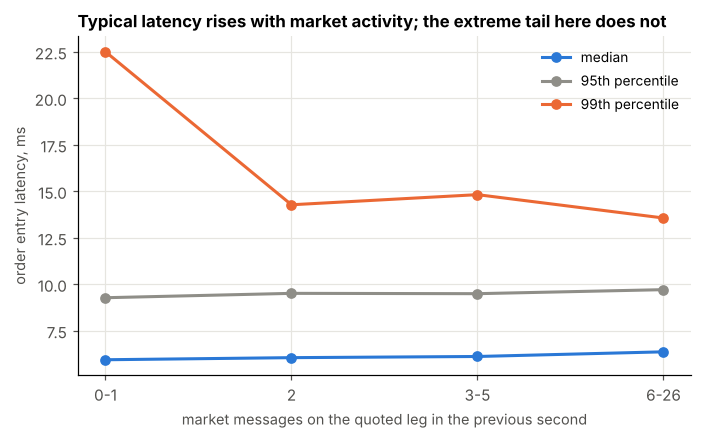

,count,50%,95%,99%
msgs_1s,,,,
"(-0.001, 1.0]",17692.0,5.94,9.28,22.51
"(1.0, 2.0]",6001.0,6.05,9.51,14.28
"(2.0, 5.0]",11369.0,6.12,9.49,14.82
"(5.0, 26.0]",8010.0,6.37,9.71,13.57


In [15]:
# latency against market activity: messages on the quoted leg in the second before each order was sent
q_orders = orders[orders.tag == "quote"].sort_values(["day", "t_submit"]).reset_index(drop=True)
activity = []
for d, g in q_orders.groupby("day", sort=True):
    ev = np.sort(np.r_[bbo[(bbo.inst == QUOTE) & (bbo.day == d)].t.values, trades[(trades.inst == QUOTE) & (trades.day == d)].t.values])
    activity.append(np.searchsorted(ev, g.t_submit.values) - np.searchsorted(ev, g.t_submit.values - 1.0))
q_orders["msgs_1s"] = np.concatenate(activity)
q_orders["entry_ms"] = (q_orders.t_arrive - q_orders.t_submit) * 1e3
lat = q_orders.groupby(pd.qcut(q_orders.msgs_1s, 4, duplicates="drop"), observed=True).entry_ms.describe(percentiles=[0.5, 0.95, 0.99])
lat = lat[["count", "50%", "95%", "99%"]]

fig, ax = plt.subplots()
x = np.arange(len(lat))
for c, col, lab in (("50%", BLUE, "median"), ("95%", GREY, "95th percentile"), ("99%", ORANGE, "99th percentile")):
    ax.plot(x, lat[c], "-o", color=col, label=lab)
lo_hi = [(max(0, int(np.floor(iv.left)) + 1), int(iv.right)) for iv in lat.index]
ax.set_xticks(x, [f"{a}" if a == b else f"{a}-{b}" for a, b in lo_hi])
ax.set_xlabel("market messages on the quoted leg in the previous second")
ax.set_ylabel("order entry latency, ms")
ax.set_title("Typical latency rises with market activity; the extreme tail here does not")
ax.legend(); plt.show()
lat.round(2)

In [16]:
# cancels that lost the race: the order filled before the cancel reached the exchange
c = orders[orders.t_cancel_req.notna()].copy()
c["cancel_ms"] = (c.t_cancel_arrive - c.t_cancel_req) * 1e3
c.groupby("cancel_reject").cancel_ms.describe(percentiles=[0.5, 0.9]).round(2)

,count,mean,std,min,50%,90%,max
cancel_reject,,,,,,,
False,41620.0,6.74,4.82,2.77,6.09,8.46,131.91
True,25.0,6.88,1.74,3.16,6.98,8.31,12.46


**Reading it.** Median and 95th-percentile latency rise with market activity, which is when quotes go stale fastest.
The 99th percentile does not, because the spikes in this dataset arrive at random. In a real system, check whether
yours do: spikes caused by load (queues, gateways, garbage collection) cluster exactly when they hurt most. Cancels
that lose the race to a fill are the direct cost: the fill you were trying to avoid. With only a few dozen of them
here, the comparison is suggestive, not conclusive.

Latency on its own is not a result. A result connects it to money: the markout of fills whose cancel was rejected,
or the hedge cost of the slowest hedges (chapter 2).

**Traps.**
- **Clocks.** Hops measured across machines need synchronised clocks. A negative latency is a clock problem, not a
  fast network.
- **Survivorship.** Only orders that reached the exchange have an arrival time. Orders lost or rejected upstream drop
  out of the latency table silently.
- **Percentiles of small samples.** A 99.9th percentile from a few thousand orders is a handful of points. Print the count.

**Exercises.**
1. Join the rejected cancels to their fills and compute their spread markouts. Are they worse than other fills from
   the same ladder level?
2. Is latency autocorrelated? Plot each order's entry latency against the previous order's. What would that mean for
   a strategy deciding whether to requote?
3. How much would cutting the 99th percentile of hedge delay in half be worth per day? Write the calculation before
   doing it.

## 7. Per-fill attribution: what one hedged fill is worth

**Question.** Putting it together, how much does a typical quote fill make, and where does it go?

For a hedged fill, in ticks of the quoted leg per unit:

$$\text{value}(h) = \underbrace{s(h)}_{\text{spread markout}} - \underbrace{\text{hedge cost}}_{\text{chapter 2}} - \underbrace{\text{fees}}_{\text{both legs}}$$

$s(h)$ already contains the edge at the fill ($h=0$) and the spread move afterwards, so it splits further into
**edge** ($s(0)$), **short-term adverse move** ($s(5) - s(0)$) and **reversion** ($s(h) - s(5)$).

In [17]:
tick_bps = TICK[QUOTE] / qf.price * 1e4                     # one quoted-leg tick in bps (about 2)
qf["hedge_cost_ticks"] = qf.hedge_cost_bps / tick_bps
qf["fee_ticks"] = (qf.fee + qf.h_fee) / (qf.qty * TICK[QUOTE])
H_HOLD = 120
qf["value"] = qf[f"s{H_HOLD}"] - qf.hedge_cost_ticks - qf.fee_ticks

parts = pd.Series({
    "edge at the fill, s(0)": qf.s0.mean(),
    "adverse move, s(5) - s(0)": (qf.s5 - qf.s0).mean(),
    f"reversion, s({H_HOLD}) - s(5)": (qf[f"s{H_HOLD}"] - qf.s5).mean(),
    "hedge cost": -qf.hedge_cost_ticks.mean(),
    "fees": -qf.fee_ticks.mean(),
})
parts["value per fill"] = parts.sum()
print(f"ticks per unit, averaged over {qf.value.notna().sum():,} quote fills (holding {H_HOLD} s):")
parts.round(3)

ticks per unit, averaged over 1,958 quote fills (holding 120 s):


edge at the fill, s(0)       0.083
adverse move, s(5) - s(0)   -0.440
reversion, s(120) - s(5)     2.487
hedge cost                  -0.591
fees                        -1.000
value per fill               0.539
dtype: float64

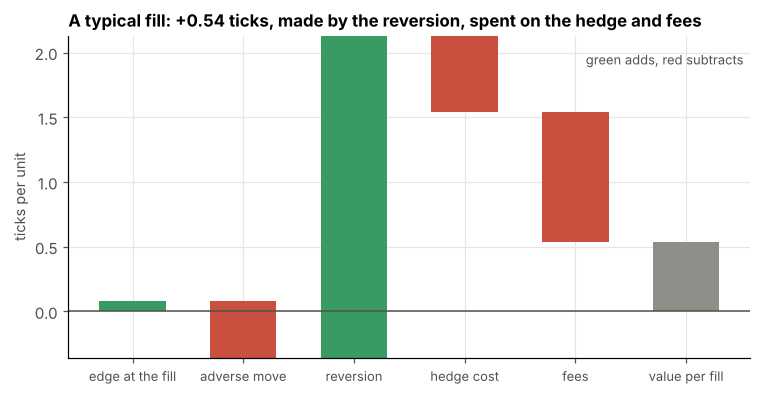

In [18]:
fig, ax = plt.subplots(figsize=(8, 3.8))
steps = parts.iloc[:-1]
run = np.r_[0, np.cumsum(steps.values)]
for i, (lab, v) in enumerate(steps.items()):
    ax.bar(i, v, bottom=run[i], color="#3a9a63" if v >= 0 else "#c9503f", width=0.6)
ax.bar(len(steps), parts.iloc[-1], color=GREY, width=0.6)
ax.axhline(0, color=INK2, lw=1)
ax.set_xticks(range(len(parts)), [s.split(",")[0] for s in parts.index], rotation=0, fontsize=8.5)
ax.set_ylabel("ticks per unit")
ax.set_title(f"A typical fill: {parts.iloc[-1]:+.2f} ticks, made by the reversion, spent on the hedge and fees")
ax.text(0.99, 0.95, "green adds, red subtracts", transform=ax.transAxes, ha="right", va="top", fontsize=8.5, color=INK2)
plt.show()

**Reading it.** This is the picture to hold in your head for a passive-quote, aggressive-hedge spread trade: a small
edge at the fill, a small loss to the move that filled you, a larger gain from the reversion, then the hedge cost.
Execution work can attack each bar separately, and this decomposition tells you which bar is big enough to bother.

"Improving execution by one tick every ten fills" is +0.1 on the value bar; set it against the value per fill in
the last row of the table to see what share of the trade's edge that is. Fees are the largest cost here (the hedge
leg's taker fee is about one quoted-leg tick per unit), which is itself a finding: a cheaper hedge route or fee tier
would be worth more than most execution tweaks.

**Traps.**
- **The holding horizon is a modelling choice.** A fixed 120 s stands in for "until the position is closed". With
  real data, use the actual exit, or mark to several horizons and show all of them.
- **Fees in the right units.** Fees are charged on notional per leg; convert them per unit of the quoted leg before
  adding them to tick-denominated markouts.

**Exercises.**
1. Redo the waterfall separately for each ladder level `k`. Which clip earns its keep?
2. Split it by the `quote_ret_2s` fifth from chapter 4. Does the most toxic fifth have the worst value, or the best?
3. Sum `value x qty x tick` over a day and compare it with that day's PnL from the strategy. What explains the gap?

## 8. Statistics hygiene: standard errors that are not lying

**Question.** Is a difference I see real?

Fills are not independent. Fills seconds apart share the same market move, so their markouts move together. The
textbook standard error $\sigma/\sqrt{n}$ assumes independence and is too small. Two honest alternatives:

- **Block bootstrap.** Cut time into blocks longer than the effect (here, 5 minutes), resample whole blocks, and
  recompute the statistic each time. The spread of the results is the standard error.
- **By-day standard error.** Treat each day as one observation. Honest but with few days very uncertain itself.

In [19]:
def block_bootstrap_se(df, col, block_s=300, reps=2000, seed=0):
    d = df.dropna(subset=[col])
    blk = d.day.astype(str) + "_" + (d.t // block_s).astype(int).astype(str)
    sums = d.groupby(blk)[col].sum().values
    counts = d.groupby(blk)[col].count().values
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(sums), size=(reps, len(sums)))
    stats = sums[idx].sum(axis=1) / counts[idx].sum(axis=1)
    return stats.std(), len(sums)


rows = []
for col in ["s1", "s5", "s30", "s120", "value"]:
    v = qf[col].dropna()
    bse, nb = block_bootstrap_se(qf, col)
    day_means = qf.groupby("day")[col].mean()
    rows.append({"metric": col, "mean": v.mean(), "naive se": v.std() / np.sqrt(len(v)), "block bootstrap se": bse,
                 "by-day se": day_means.std() / np.sqrt(len(day_means)), "fills": len(v), "blocks": nb})
se = pd.DataFrame(rows).set_index("metric")
se["bootstrap / naive"] = se["block bootstrap se"] / se["naive se"]
se.round(3)

,mean,naive se,block bootstrap se,by-day se,fills,blocks,bootstrap / naive
metric,,,,,,,
s1,-0.675,0.037,0.075,0.081,2040,72,2.054
s5,-0.353,0.054,0.109,0.046,2026,72,2.002
s30,1.092,0.093,0.218,0.202,1992,72,2.331
s120,2.102,0.116,0.240,0.123,1958,71,2.062
value,0.515,0.117,0.240,0.123,1958,71,2.058


**Reading it.** The block-bootstrap standard error is about twice the naive one at every horizon, because nearby fills
share the same market move. A difference that is "three standard errors" on the naive scale can be noise. The by-day
standard error jumps around (for one metric it is even below the naive one): with six days, it is itself estimated
from six numbers. Few clusters give an unreliable standard error, whichever way it errs.

**More traps.**
- **Multiple comparisons.** Scan 80 buckets and about four will clear two standard errors by chance. Decide the
  comparison before you look, or confirm what you find on days you did not look at.
- **Placebo tests.** Shift the feature in time (use the value from an hour earlier) and redo the table. If the
  "effect" survives, it was never about that feature.
- **Effect size over significance.** A real effect of 0.05 ticks may not be worth a line of code. Always translate
  into money per day.

**Exercises.**
1. Redo the bootstrap with 30-second and 30-minute blocks. How does the standard error change, and what does that
   tell you about how long the correlation lasts?
2. Run a placebo on chapter 4's `quote_ret_2s` table: use the feature from 600 seconds before each fill. What do you
   expect, and what do you see?

# Part II. Simple machine learning for trade optimisation

## 9. Framing: prediction, decision, money

Machine learning earns its place in trade optimisation only through a decision. Every use has the same chain:

| Step | Question | Example |
| --- | --- | --- |
| Target | What exactly are we predicting, over what horizon? | "Will this order fill within its life?"; "spread markout 1 s after this fill" |
| Features | What is known at the decision time, and only then? | book state, recent moves and flow, our queue position |
| Model | The simplest one that beats a baseline out of sample | logistic or linear regression first; gradient-boosted trees second |
| Decision | What do we do differently because of the prediction? | quote one tick wider; pull quotes; size the hedge differently |
| Value | Does the decision make money, measured the same way as everything else? | change in value per day, with an honest standard error |

Three rules carry most of the weight:
1. **Baseline first.** A constant, or the one obvious feature. A model that cannot beat it is not a model.
2. **Validate across time.** Train on some days, test on others. Random splits leak the future (chapter 12).
3. **Judge in money, not accuracy.** A model can be right about the target and still lead to a bad decision (chapter 11).

What practitioners report working for this kind of problem is unglamorous: linear and logistic models on a handful
of features that make economic sense, gradient-boosted trees when interactions matter, and careful validation. Deep
learning is rarely the bottleneck. The work is in the target, the features and the test.

`scikit-learn` is used below; everything here also runs with `statsmodels` or plain `numpy`.

In [20]:
from sklearn.calibration import calibration_curve
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import log_loss, r2_score, roc_auc_score
from sklearn.model_selection import GroupKFold, KFold, cross_val_predict

TRAIN_DAYS, TEST_DAYS = [0, 1, 2, 3], [4, 5]

## 10. A fill-probability model

**Question.** Given where we place an order and what the book looks like, how likely is it to fill?

**Target.** `got_fill` (1 if the order received any fill). **Features**, all known when the order arrives: distance
behind the touch in ticks, log of the size ahead of us, and the spread in ticks. **Model.** Logistic regression.
**Validation.** Train on four days, test on the other two. **Metric.** Log loss (lower is better), against a constant
(the base rate) and against distance alone.

In [21]:
fp = qo[qo.dist.between(-1, 6)].copy()
fp["log_ahead"] = np.log1p(fp.ahead0)
train, test = fp[fp.day.isin(TRAIN_DAYS)], fp[fp.day.isin(TEST_DAYS)]

results, models = [], {}
base = train.got_fill.mean()
results.append({"model": "constant (base rate)", "log loss": log_loss(test.got_fill, np.full(len(test), base)), "AUC": 0.5})
for name, cols in [("distance only", ["dist"]), ("+ queue ahead", ["dist", "log_ahead"]),
                   ("+ spread", ["dist", "log_ahead", "spread_ticks"])]:
    m = LogisticRegression(max_iter=1000).fit(train[cols], train.got_fill)
    p = m.predict_proba(test[cols])[:, 1]
    models[name] = (m, cols)
    results.append({"model": name, "log loss": log_loss(test.got_fill, p), "AUC": roc_auc_score(test.got_fill, p)})
print(f"train {len(train):,} orders, test {len(test):,} orders, base rate {base:.1%}")
pd.DataFrame(results).set_index("model").round(4)

train 17,091 orders, test 8,212 orders, base rate 5.8%


,log loss,AUC
model,,
constant (base rate),0.212,0.500
distance only,0.120,0.933
+ queue ahead,0.119,0.931
+ spread,0.118,0.935


coefficients (log-odds per unit):
dist           -1.044
log_ahead      -0.185
spread_ticks   -0.575
dtype: float64

odds multiplier per unit:
dist            0.352
log_ahead       0.831
spread_ticks    0.563
dtype: float64


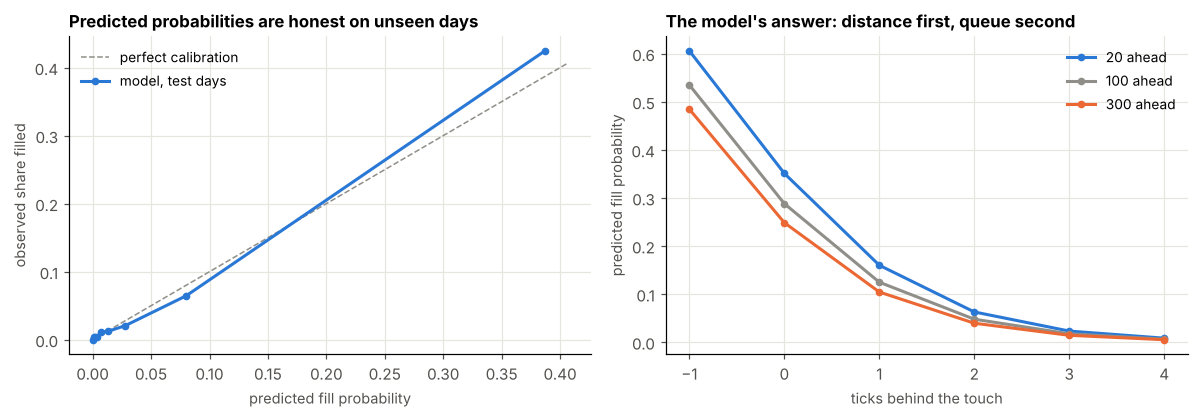

In [22]:
m, cols = models["+ spread"]
coef = pd.Series(m.coef_[0], index=cols)
print("coefficients (log-odds per unit):"); print(coef.round(3))
print("\nodds multiplier per unit:"); print(np.exp(coef).round(3))

p_test = m.predict_proba(test[cols])[:, 1]
frac_pos, mean_pred = calibration_curve(test.got_fill, p_test, n_bins=10, strategy="quantile")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.9))
ax[0].plot([0, max(mean_pred) * 1.05], [0, max(mean_pred) * 1.05], color=GREY, lw=1, ls="--", label="perfect calibration")
ax[0].plot(mean_pred, frac_pos, "-o", color=BLUE, ms=4, label="model, test days")
ax[0].set_xlabel("predicted fill probability"); ax[0].set_ylabel("observed share filled")
ax[0].set_title("Predicted probabilities are honest on unseen days"); ax[0].legend()
grid = pd.DataFrame({"dist": np.repeat(np.arange(-1, 5), 3), "log_ahead": np.tile(np.log1p([20, 100, 300]), 6),
                     "spread_ticks": 1})
grid["p"] = m.predict_proba(grid[cols])[:, 1]
for la, col, lab in zip(np.log1p([20, 100, 300]), [BLUE, GREY, ORANGE], ["20 ahead", "100 ahead", "300 ahead"]):
    g = grid[np.isclose(grid.log_ahead, la)]
    ax[1].plot(g.dist, g.p, "-o", color=col, ms=4, label=lab)
ax[1].set_xlabel("ticks behind the touch"); ax[1].set_ylabel("predicted fill probability")
ax[1].set_title("The model's answer: distance first, queue second"); ax[1].legend()
plt.tight_layout(); plt.show()

**Reading it.** Distance carries most of the information, queue and spread add a little, and the probabilities are
well calibrated on days the model never saw. Calibration matters more than AUC here: the use of this model is to
turn "move the clip a tick" into an expected number of fills, so the probability itself has to be right.

**How it gets used.** Combine it with chapter 4: expected value of quoting at distance $d$ is
$P(\text{fill} \mid d) \times E[\text{value} \mid \text{fill at } d]$. That product, as a function of $d$, is the
placement curve.

**Traps.**
- **Leaky features.** `life_s` (how long the order lived) would improve the fit, but it is known only after the
  order ends. Add it and watch the test score: a small improvement from a leaky feature is still a leak.
- **The decision changes the data.** If the strategy starts quoting where the model says, the orders it sends are no
  longer like the training orders. Refit and recheck after any change.

**Exercises.**
1. Add `life_s` as a feature. How much does the score improve, and why is the improved model useless?
2. Fit separate models for buys and sells. Should they differ? What would it mean if they did?
3. Use the model to estimate daily fills if every clip were one tick further out. Compare with the simple table
   estimate from chapter 5's exercise 3.

## 11. A toxicity model, and why the obvious decision loses money

**Question.** Can we predict which fills will mark out badly, and does avoiding them help?

**Target.** Two versions: the spread markout 1 second after the fill (`s1`, short-term toxicity), and the value of the
fill at the trade's horizon (`value`, chapter 7). **Features**, known at the fill: chapter 4's four plus the spread.
**Models.** Ridge regression and gradient-boosted trees. **Validation.** Leave-one-day-out: train on five days,
predict the sixth, six times.

In [23]:
FEATS = ["quote_ret_2s", "hedge_ret_2s", "flow_5s", "lean", "spread_ticks"]
tx = qf.assign(spread_ticks=lambda x: np.round((x.ask - x.bid) / TICK[QUOTE])).dropna(subset=FEATS + ["s1", "value"]).copy()
by_day = GroupKFold(n_splits=tx.day.nunique())
MODELS = {"ridge": lambda: Ridge(alpha=1.0),
          "boosted trees": lambda: HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=200)}

scores, preds = [], {}
for target in ["s1", "value"]:
    for name, make in MODELS.items():
        p = cross_val_predict(make(), tx[FEATS], tx[target], cv=by_day, groups=tx.day)
        preds[(target, name)] = p
        scores.append({"target": target, "model": name, "out-of-sample R2": r2_score(tx[target], p),
                       "corr(pred, actual)": np.corrcoef(p, tx[target])[0, 1]})
pd.DataFrame(scores).set_index(["target", "model"]).round(3)

out-of-sample R2  corr(pred, actual)
target model                                              
s1     ridge                     0.046               0.223
       boosted trees            -0.003               0.162
value  ridge                    -0.005               0.044
       boosted trees            -0.103              -0.052

The short-term target is weakly predictable, and the simple linear model does at least as well as the trees. The
value target is not predictable from these features at all. Both are normal results: short-horizon toxicity is
driven by the move already under way, which the features see; where the spread goes over two minutes is mostly not
in the book at the fill.

Now the decision. The obvious use of a toxicity model is: **when it predicts a toxic fill, do not be there** (pull or
widen the quotes). Approximate that by removing the fills it flags, and value what is left at the trade's horizon.

In [24]:
rows = []
for target in ["s1", "value"]:
    p = preds[(target, "ridge")]
    for share in [0.1, 0.2, 0.3]:
        flagged = p <= np.quantile(p, share)
        rows.append({"model trained on": target, "share of fills avoided": share,
                     "value of avoided fills (ticks/fill)": tx.value.values[flagged].mean(),
                     "value of kept fills (ticks/fill)": tx.value.values[~flagged].mean(),
                     "change in total value (ticks x units)": -(tx.value.values[flagged] * tx.qty.values[flagged]).sum()})
decision = pd.DataFrame(rows).set_index(["model trained on", "share of fills avoided"])
print(f"all fills: {tx.value.mean():.2f} ticks per fill on average")
decision.round(2)

all fills: 0.52 ticks per fill on average


value of avoided fills (ticks/fill)  value of kept fills (ticks/fill)  change in total value (ticks x units)
model trained on share of fills avoided                                                                                                              
s1               0.1                                                    1.32                              0.43                               -1892.87
                 0.2                                                    1.06                              0.38                               -3659.33
                 0.3                                                    1.01                              0.30                               -4941.60
value            0.1                                                   -0.18                              0.59                                 208.15
                 0.2                                                    0.09                              0.62                                -131.84
                 0.3                                                    0.12                              0.69                                -402.23

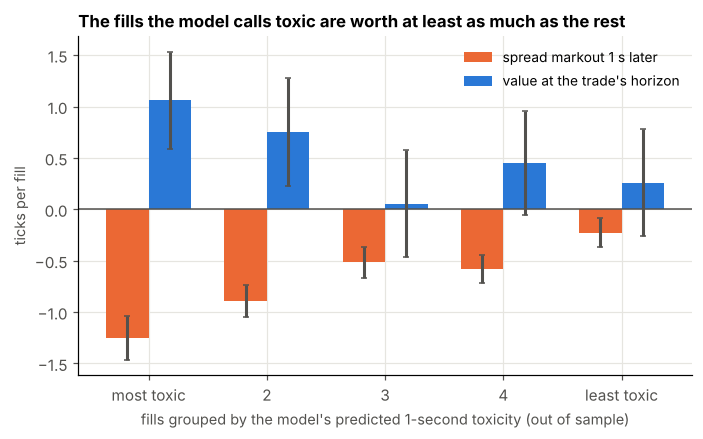

,s1,value,s1_se,value_se
toxicity_fifth,,,,
most toxic,-1.25,1.06,0.11,0.24
2,-0.89,0.75,0.08,0.27
3,-0.51,0.05,0.08,0.26
4,-0.58,0.45,0.07,0.26
least toxic,-0.23,0.26,0.07,0.27


In [25]:
p = preds[("s1", "ridge")]
tx["toxicity_fifth"] = pd.qcut(p, 5, labels=["most toxic", "2", "3", "4", "least toxic"])
g = tx.groupby("toxicity_fifth", observed=True)
tb = pd.DataFrame({"s1": g.s1.mean(), "value": g.value.mean(),
                   "s1_se": g.s1.std() / np.sqrt(g.size()), "value_se": g.value.std() / np.sqrt(g.size())})
fig, ax = plt.subplots()
x = np.arange(len(tb))
ax.bar(x - 0.18, tb.s1, 0.36, yerr=1.96 * tb.s1_se, color=ORANGE, label="spread markout 1 s later", error_kw={"ecolor": INK2, "capsize": 2})
ax.bar(x + 0.18, tb.value, 0.36, yerr=1.96 * tb.value_se, color=BLUE, label="value at the trade's horizon", error_kw={"ecolor": INK2, "capsize": 2})
ax.axhline(0, color=INK2, lw=1)
ax.set_xticks(x, tb.index)
ax.set_xlabel("fills grouped by the model's predicted 1-second toxicity (out of sample)")
ax.set_ylabel("ticks per fill")
ax.set_title("The fills the model calls toxic are worth at least as much as the rest")
ax.legend(loc="upper right"); plt.show()
tb.round(2)

**Reading it.** The model is right about what it was trained on: the fills it calls toxic do mark out worse over the
next second. But at the horizon that pays they are worth at least as much as the rest, because the move that makes
them toxic is the dislocation that later reverts. Avoiding them loses money at every share tried. A model trained on
the value directly shows a small gain at the smallest share and a loss at the largest, from a model whose
out-of-sample R2 is below zero: treat that gain as noise until it survives a proper test (exercise 4).

This is the most important lesson in the notebook, and it is the same one chapter 3 made with plain markouts: **the
target defines the decision**. A target chosen because it is easy to predict, rather than because it is what the
trade earns, produces a confident model and a bad rule.

When a short-horizon toxicity model *is* useful: for the hedge (time the hedge around predicted short-term moves),
for a strategy that flattens quickly, or as a feature in a model of the right target.

**Traps.**
- "Removing flagged fills" is an approximation. Pulling quotes also changes which other fills you get and your queue
  position. Treat this as a screen; confirm with a replay or a live test.
- Feature scaling: ridge penalises coefficients, so features on different scales are penalised unequally. Standardise
  them (a `StandardScaler` in a `Pipeline`) before reading coefficient sizes.

**Exercises.**
1. Train on `s5`, `s30` and `s120` as targets in turn. At what horizon does the decision "avoid predicted toxic fills"
   stop losing money?
2. Use the 1-second toxicity prediction for the *hedge* instead: hedge immediately when it is high, wait 200 ms when
   it is low. What would you need from these tables to estimate the value of that rule?
3. Fit the ridge on standardised features and read the coefficients. Which feature matters most, and does that agree
   with chapter 4's tables?
4. Is the value-trained model's small gain at 10% real? Put a block-bootstrap standard error (chapter 8) on the change
   in total value, and decide before you compute it what you will conclude at each possible answer.

## 12. Validation: time-blocked splits, overlapping labels, leakage

**Question.** How do I know a model's score is real?

Two ways a score lies:

1. **Overlapping labels.** Fills seconds apart share the same future path. A random split puts one in training and its
   neighbour in testing, so the model is tested on outcomes it has effectively seen. Split by time (whole days here,
   or long blocks with a gap between training and test, the "purge and embargo" idea from López de Prado).
2. **Leaked features.** A feature computed with information from after the decision. The classic in fill analysis:
   using **your own receive time** for a fill instead of the exchange time. The receive time is later, so the book
   at that time already contains the move after the fill.

In [26]:
tx = tx.sort_values(["day", "t"]).reset_index(drop=True)
leak = []
for d, g in tx.groupby("day", sort=True):
    leak.append(g.side.values * (mid_at(QUOTE, d, g.t_local.values) - g.price.values) / TICK[QUOTE])
tx["mid_at_receive_time"] = np.concatenate(leak)      # LEAKS: the book when we heard about the fill, a few ms later
print(f"median gap between fill time and our receive time: {(tx.t_local - tx.t).median() * 1e3:.1f} ms")

schemes = {"random 5-fold": (KFold(5, shuffle=True, random_state=0), None),
           "leave one day out": (GroupKFold(tx.day.nunique()), tx.day)}
rows = []
for target in ["s1", "s120"]:
    for feats, fname in [(FEATS, "honest features"), (FEATS + ["mid_at_receive_time"], "+ leaked feature")]:
        for sname, (cv, groups) in schemes.items():
            for mname, make in MODELS.items():
                p = cross_val_predict(make(), tx[feats], tx[target], cv=cv, groups=groups)
                rows.append({"target": target, "features": fname, "validation": sname, "model": mname,
                             "R2": r2_score(tx[target], p)})
val = pd.DataFrame(rows).pivot_table(index=["target", "features", "model"], columns="validation", values="R2")
val.round(3)

median gap between fill time and our receive time: 5.3 ms


validation                             leave one day out  random 5-fold
target features         model                                          
s1     + leaked feature boosted trees              0.138          0.255
                        ridge                      0.180          0.197
       honest features  boosted trees             -0.003          0.131
                        ridge                      0.046          0.070
s120   + leaked feature boosted trees             -0.105          0.035
                        ridge                     -0.004          0.009
       honest features  boosted trees             -0.102          0.041
                        ridge                     -0.004          0.009

**Reading it.** Look along each row. With honest features, random 5-fold makes the boosted trees look predictive,
and leave-one-day-out shows that was the trees memorising each day's path through neighbouring fills. The linear
model, which cannot memorise much, is far less flattered. With the leaked feature, the short-horizon score jumps under
both schemes: no split saves you from a feature that contains the answer.

A practical checklist for any model score:
- Was it computed on days (or long blocks) the model never saw?
- Could every feature have been computed by the strategy at the decision time, from data it had then?
- Does a flexible model beat a simple one by much more out of sample than in sample? If so, suspect memorising.
- Does the score survive a placebo (features shifted far back in time)?

**Exercises.**
1. Implement a purged split: train on the first 70% of each day, test on the last 20%, and drop the 10% in between.
   How do the scores compare with leave-one-day-out?
2. Find another leaked feature hiding in the tables (hint: look at the order columns). Prove it leaks.

## 13. A hedge-cost regression you can explain to a trader

**Question.** What drives the cost of crossing on the hedge leg, in units a trader can act on?

Not every model needs to be a predictor. A linear regression whose coefficients have units is a compact way to
describe a cost. Here: crossing cost in bps against the half-spread at arrival and the hedge size relative to the
size at the touch.

In [27]:
hf1 = (h_fills.sort_values(["day", "order_id", "t"]).groupby(["day", "order_id"]).first()
       [["bid", "ask", "bid_qty", "ask_qty"]])
hc = hdg.join(hf1, on=["day", "id"]).dropna(subset=["cross_cost", "bid"]).copy()
hc["half_spread_bps"] = (hc.ask - hc.bid) / 2 / hc.mid_arrive * 1e4
hc["touch_qty"] = np.where(hc.side > 0, hc.ask_qty, hc.bid_qty)
hc["size_over_touch"] = (hc.qty / hc.touch_qty).clip(upper=5)

X = hc[["half_spread_bps", "size_over_touch"]]
reg = LinearRegression().fit(X, hc.cross_cost)
coefs = pd.Series({"intercept": reg.intercept_, **dict(zip(X.columns, reg.coef_))})

# standard errors by block bootstrap over 5-minute blocks
blk = hc.day.astype(str) + "_" + (hc.t_submit // 300).astype(int).astype(str)
groups = {b: idx for b, idx in hc.groupby(blk).groups.items()}
keys = list(groups); rng = np.random.default_rng(1); boot = []
for _ in range(500):
    sel = np.concatenate([groups[k] for k in rng.choice(keys, len(keys))])
    s = hc.loc[sel]
    r = LinearRegression().fit(s[X.columns], s.cross_cost)
    boot.append([r.intercept_, *r.coef_])
coefs = pd.DataFrame({"estimate": coefs, "se (block bootstrap)": np.std(boot, axis=0)})
print(f"R2 = {reg.score(X, hc.cross_cost):.3f} on {len(hc):,} hedge orders")
coefs.round(3)

R2 = 0.671 on 2,058 hedge orders


,estimate,se (block bootstrap)
intercept,0.075,0.029
half_spread_bps,0.925,0.024
size_over_touch,0.220,0.007


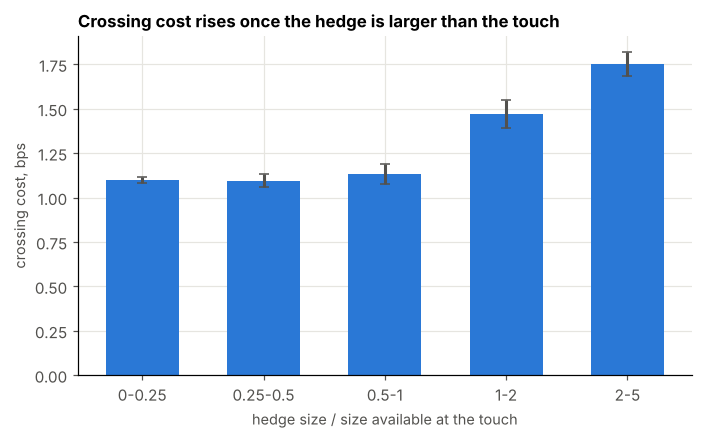

,mean,count,se
size_over_touch,,,
"(0.0, 0.25]",1.097,1177,0.009
"(0.25, 0.5]",1.096,343,0.017
"(0.5, 1.0]",1.132,238,0.030
"(1.0, 2.0]",1.470,145,0.041
"(2.0, 5.0]",1.750,155,0.034


In [28]:
b = hc.groupby(pd.cut(hc.size_over_touch, [0, 0.25, 0.5, 1, 2, 5]), observed=True).cross_cost.agg(["mean", "count"])
b["se"] = hc.groupby(pd.cut(hc.size_over_touch, [0, 0.25, 0.5, 1, 2, 5]), observed=True).cross_cost.std() / np.sqrt(b["count"])
fig, ax = plt.subplots()
x = np.arange(len(b))
ax.bar(x, b["mean"], yerr=1.96 * b["se"], color=BLUE, width=0.6, error_kw={"ecolor": INK2, "capsize": 3})
ax.set_xticks(x, [f"{iv.left:g}-{iv.right:g}" for iv in b.index])
ax.set_xlabel("hedge size / size available at the touch")
ax.set_ylabel("crossing cost, bps")
ax.set_title("Crossing cost rises once the hedge is larger than the touch")
plt.show()
b.round(3)

**Reading it.** The coefficient on the half-spread should be close to 1 (you pay the half-spread you cross), and the
size coefficient says what each extra multiple of the touch costs. Those two numbers are the kind of result a trader
can use directly: "split hedges larger than the touch" or "hedge less aggressively when the hedge leg's spread is wide".

**Exercises.**
1. Add the market activity in the previous second (chapter 6) as a feature. Does it explain cost beyond the spread?
2. Fit the same regression with the *delay* cost as the target. Which features matter for that, and why are they
   different?

# Checklist and next steps

### A post-trade triage order

When a strategy's execution needs looking at, in this order:

1. **Attribution** (chapter 7). Which bar is big: edge, adverse move, reversion, hedge cost, fees? Work on the big one.
2. **Markout curves** (chapter 3), spread markouts for hedged trades, at horizons set by the trade.
3. **Conditional markouts** (chapter 4) on a few features known at the fill. Check each against a placebo.
4. **Hedge cost** (chapters 2 and 13): delay versus crossing; size versus the touch.
5. **Fill probability** (chapters 5 and 10): what a placement change does to the number of fills.
6. **Latency** (chapter 6), always connected back to one of the above in money.
7. **One fill at a time.** Take the worst fills from each table and reconstruct their timelines from the raw data.

### Mapping to your own data

| This notebook | What you build from |
| --- | --- |
| `fills` with `parent` | exchange or gateway fill reports; link each hedge to its quote fill by order tags or by time |
| `orders` timestamps | gateway audit trail plus your own logs (the hops differ per system; keep them separate) |
| `bbo`, `trades` | market data for both legs, exchange-timestamped |
| `fair` | the strategy's own log of its fair value |
| `ahead0` | estimated from level-2 data at order arrival, or from order-by-order data if the venue offers it |

### Reading list

- Cartea, Jaimungal and Penalva, *Algorithmic and High-Frequency Trading* (2015): fill probabilities, adverse
  selection and optimal placement, with the models behind them.
- Bouchaud, Bonart, Donier and Gould, *Trades, Quotes and Prices* (2018): what order books do, and impact.
- López de Prado, *Advances in Financial Machine Learning* (2018), chapters 4 and 7: overlapping labels, purged
  cross-validation and leakage.
- Hasbrouck, *Empirical Market Microstructure* (2007): the econometrics of trades and quotes.

### One closing caution

The data here is simulated. The effects in it were planted to be findable, and their sizes are invented. Everything
in the method transfers; none of the numbers do. Run each chapter on your own fills and expect different answers.